# RQ3 — What happens to contested events when a confidence threshold decides what is automated, and how can we do better?

This notebook reproduces **§3.4 (RQ3)** and **§3.5 (How could we improve HITL routing?)** of the paper:
the outcomes of a .90 threshold, what passes through it, the direction of the models' readings on the
protest boundary, routing at a fixed review budget (Appendix Table *Routing*), the alternative routing
signals (Appendix Table *Alternative routing signals*), and the two figures *Outcomes of a confidence
threshold* and *The triage trade-off*.

All code is in the cells below. Inputs: the Label Studio exports and the stored model scores in `ls_real/`.
Run the cells from top to bottom; the routing simulation in Step 4 takes several minutes.

**Contents**
0. From Label Studio exports to readings; the model scores
1. The population and the groups
2. A .90 threshold: what is auto-accepted, and what passes through
3. Indifferent, but not neutral: the direction of the models' readings
4. Routing at a fixed review budget (confidence, category, two buckets)
5. Alternative routing signals
6. Figures
7. Recap

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

# The data lives in ls_real/ at the root of the redress_paper folder. Walk up from the
# notebook's folder until we find it, and work from there so that all paths are relative.
REPO = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(REPO, 'ls_real')):
    parent = os.path.dirname(REPO)
    if parent == REPO:
        raise FileNotFoundError('Run this notebook from inside the redress_paper folder (ls_real/ not found).')
    REPO = parent
os.chdir(REPO)
D = 'ls_real'
FIG_DIR = os.path.join('rq_notebooks', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 60)
print('working directory:', REPO)

working directory: c:\Users\tessd\RedressHub_paper


## Step 0 — from Label Studio exports to *readings*

The double-annotated dataset is stored as pairs of Label Studio exports in `ls_real/`. Each pair
covers the same texts, annotated independently by two annotators (a *pool*):

| pool | annotator A | annotator B | pair |
|---|---|---|---|
| `iaa` | Cira (re-annotation) | Elke (re-annotation) | domain experts |
| `cira_solo` | Cira (hesitancy added retrospectively) | Elke (in the moment) | domain experts |
| `elke_solo` | Elke (hesitancy added retrospectively) | Cira (in the moment) | domain experts |
| `iaa_nl` | Elke (re-annotation) | trained annotator A3 | expert × trained |
| `elke_solo_nl` | Elke (hesitancy added retrospectively) | trained annotator A3 | expert × trained |

The code below turns every labelled span into one **reading** (paper, §1.1): one annotator's label on
one span. For each reading we look for the partner annotator's spans that overlap it by at least one
character:

* `other_label` — the label of the partner's span with the largest overlap (empty if the partner marked
  nothing there: a *one-sided* span);
* `divergent` — 1 if none of the overlapping partner spans has the same label;
* `friction` — 1 if the reading is divergent **or** the annotator rated it *somewhat* or *very hesitant*;
* `ftype` — `agreed` (no friction), `contested` (friction, and the partner marked the passage too) or
  `detection` (only this annotator marked the passage).

Three spans were accidentally labelled twice (same span, same label) by the same annotator; we keep one
copy of each (`dedup=True`). Two other spans deliberately carry two different labels (an event type and
`Organisation`); both readings are kept. One Dutch article was annotated twice, in two different pools;
we keep one copy (`EXCLUDE_TEXTS`, see the duplicate check in the RQ1 notebook). The three vaguer *Time*
labels are left out of the analysis, as in the paper.

**No article texts.** The articles remain under their publishers' copyright, so the exports contain only
character offsets, no text. `ls_real/texts.csv` lists, for every text, its source URL, source, language,
length and a SHA-256 checksum of the exact text that was annotated. None of the analyses needs the texts
themselves. If the full texts are available locally (project members: see the README), `load_texts()`
returns them, and the notebooks then also show the span texts and re-run the duplicate check from scratch.

In [2]:
RATING = {'certain': 0, 'mostly certain': 1, 'somewhat hesitant': 2, 'very hesitant': 3}
NAME = {1182: 'Cira', 1188: 'Elke', 644: 'A3'}             # Label Studio user id -> annotator
POOLS = [  # pool, export of annotator A, export of annotator B (same texts), annotator pair
    ('iaa', 'export_reann_cira.json', 'export_reann_elke.json', 'expert-expert'),
    ('cira_solo', 'export_hesretro_cira.json', 'export_cross_elke.json', 'expert-expert'),
    ('elke_solo', 'export_hesretro_elke.json', 'export_cross_cira.json', 'expert-expert'),
    ('iaa_nl', 'export_reann_elke_nl.json', 'export_reann_a3.json', 'expert-trained'),
    ('elke_solo_nl', 'export_hesretro_elke_nl.json', 'export_cross_a3.json', 'expert-trained'),
]
# descriptive labels; every other label is normative
STRATUM = {'Organisation': 'descriptive', 'Time_absolute': 'descriptive',
           'Books': 'descriptive', 'Location': 'descriptive'}
DROP = {'Time_relative', 'Time_range', 'Time_vague'}         # left out of the analysis
KEYS = ['text_key', 'annotator', 'start', 'end']              # identifies one reading
# The same Dutch article was annotated twice, once in the iaa_nl pool and once in the elke_solo_nl pool
# (see the duplicate check in the RQ1 notebook). We keep the iaa_nl copy, in which both annotators rated
# their hesitancy while annotating, and leave out the other copy.
EXCLUDE_TEXTS = {'elke_solo_nl:335223'}
# one row per text: source URL, source, language, length and SHA-256 checksum of the annotated text
TEXT_META = pd.read_csv(os.path.join(D, 'texts.csv')).set_index('text_key')


def load_texts():
    """The full annotated texts, if available locally (ls_real/texts_full.json, or exports that still contain
    the texts); otherwise None. Each text is checked against its checksum in texts.csv."""
    import hashlib
    path = os.path.join(D, 'texts_full.json')
    texts = json.load(open(path, encoding='utf-8')) if os.path.exists(path) else {}
    if not texts:
        for pool, fa, fb, pair in POOLS:
            for f in (fa, fb):
                for t in json.load(open(os.path.join(D, f), encoding='utf-8')):
                    if 'text' in t['data']:
                        texts[f'{pool}:{t["data"]["orig_task_id"]}'] = t['data']['text']
    for k, v in texts.items():
        assert hashlib.sha256(v.encode('utf-8')).hexdigest() == TEXT_META.loc[k, 'sha256'], f'{k}: checksum mismatch'
    return texts or None


def parse(task, drop, collapse):
    """Spans and per-span choices (hesitancy, alternative label, source of doubt) of one annotation."""
    canon = lambda label: collapse.get(label, label)
    ann = [a for a in task['annotations'] if not a.get('was_cancelled')][0]
    spans = [dict(id=r['id'], start=r['value']['start'], end=r['value']['end'], label=canon(r['value']['labels'][0]))
             for r in ann['result'] if r.get('type') == 'labels' and canon(r['value']['labels'][0]) not in drop]
    choices = {'hesitancy': {}, 'alt_label': {}, 'doubt_source': {}}
    for r in ann['result']:
        if r.get('type') == 'choices' and r.get('from_name') in choices:
            v = r['value']['choices'][0]
            if r['from_name'] == 'alt_label':
                v = canon(v)
                if v in drop:
                    continue
            choices[r['from_name']][r['id']] = v
    return ann['completed_by'], spans, choices


def overlap(a, b):
    """Two spans overlap if they share at least one character."""
    return a['start'] < b['end'] and b['start'] < a['end']


def rows_for(task, other_task, pool, pair, drop, collapse, stratum):
    """One row (reading) per span of `task`, compared with the partner's annotation `other_task`."""
    user, spans, choices = parse(task, drop, collapse)
    _, other_spans, _ = parse(other_task, drop, collapse)
    text_key = f'{pool}:{task["data"]["orig_task_id"]}'
    mode = 'retrospective' if task['data'].get('arm') == 'retrospective' else 'in-the-moment'
    out = []
    for s in spans:
        cands = [o for o in other_spans if overlap(s, o)]
        matched = any(o['label'] == s['label'] for o in cands)
        other_label = (max(cands, key=lambda o: min(s['end'], o['end']) - max(s['start'], o['start']))['label']
                       if cands else None)
        out.append(dict(pool=pool, pair=pair, text_key=text_key,
                        annotator=NAME.get(user, user), mode=mode, lang=TEXT_META.loc[text_key, 'lang'],
                        start=s['start'], end=s['end'], label=s['label'],
                        stratum=stratum.get(s['label'], 'normative'),
                        hesitancy=RATING[choices['hesitancy'][s['id']]],
                        alt_label=choices['alt_label'].get(s['id']),
                        doubt_source=choices['doubt_source'].get(s['id']),
                        other_label=other_label, divergent=int(not matched)))
    return out


def build_readings(drop=DROP, collapse=None, stratum=STRATUM, dedup=True, exclude=EXCLUDE_TEXTS):
    collapse = collapse or {}
    rows = []
    for pool, fa, fb, pair in POOLS:
        a = {t['data']['orig_task_id']: t for t in json.load(open(os.path.join(D, fa), encoding='utf-8'))}
        b = {t['data']['orig_task_id']: t for t in json.load(open(os.path.join(D, fb), encoding='utf-8'))}
        assert set(a) == set(b), f'{pool}: the two exports do not cover the same texts'
        for k in a:
            if f'{pool}:{k}' in exclude:
                continue
            rows += rows_for(a[k], b[k], pool, pair, drop, collapse, stratum)
            rows += rows_for(b[k], a[k], pool, pair, drop, collapse, stratum)
    df = pd.DataFrame(rows)
    df['friction'] = ((df.divergent == 1) | (df.hesitancy >= 2)).astype(int)
    if dedup:  # three spans were accidentally labelled twice (same span, same label) by the same annotator
        df = df.drop_duplicates(KEYS + ['label']).reset_index(drop=True)
    df['ftype'] = np.where(df.friction == 0, 'agreed', np.where(df.other_label.notna(), 'contested', 'detection'))
    # 'first' marks the readings of one (alphabetically first) annotator per text, so that each
    # label split is counted once rather than once per annotator
    who = df.groupby('text_key').annotator.agg(lambda s: sorted(set(s)))
    df['first'] = [a == who[k][0] for k, a in zip(df.text_key, df.annotator)]
    return df


def passages(frame):
    """Passage id per reading: readings whose spans overlap (directly or via a chain) share a passage."""
    pid = np.full(len(frame), -1)
    nxt = 0
    for _, g in frame.groupby('text_key'):
        idx = g.index.values
        s, e = g.start.values, g.end.values
        parent = list(range(len(idx)))
        def find(i):
            while parent[i] != i:
                parent[i] = parent[parent[i]]
                i = parent[i]
            return i
        for i in range(len(idx)):
            for j in range(i + 1, len(idx)):
                if s[i] < e[j] and s[j] < e[i]:
                    parent[find(i)] = find(j)
        roots = {}
        for i in range(len(idx)):
            r = find(i)
            if r not in roots:
                roots[r] = nxt
                nxt += 1
            pid[frame.index.get_loc(idx[i])] = roots[r]
    return pid

In [3]:
df = build_readings()
df['pid'] = passages(df)
print(f'{len(df)} readings in {df.text_key.nunique()} texts')
df[['pool', 'pair', 'text_key', 'annotator', 'label', 'stratum', 'hesitancy', 'other_label', 'divergent', 'ftype']].head(8)

1469 readings in 67 texts


,pool,pair,text_key,annotator,label,stratum,hesitancy,other_label,divergent,ftype
0,iaa,expert-expert,iaa:285647,Cira,Truth-seeking initiatives,normative,0,Truth-seeking initiatives,0,agreed
1,iaa,expert-expert,iaa:285647,Cira,Truth-seeking initiatives,normative,0,Truth-seeking initiatives,0,agreed
2,iaa,expert-expert,iaa:285647,Cira,Time_absolute,descriptive,0,None,1,detection
3,iaa,expert-expert,iaa:285647,Cira,Public acknowledgements,normative,0,Apologies,1,contested
4,iaa,expert-expert,iaa:285647,Cira,Organisation,descriptive,0,Organisation,0,agreed
5,iaa,expert-expert,iaa:285647,Cira,Time_absolute,descriptive,0,None,1,detection
6,iaa,expert-expert,iaa:285647,Cira,Time_absolute,descriptive,2,None,1,detection
7,iaa,expert-expert,iaa:285647,Cira,Truth-seeking initiatives,normative,2,Truth-seeking initiatives,0,contested


### The model scores

The LLM outputs were computed once and are stored as CSV files in `ls_real/` (one row per reading;
re-running the API calls is not needed to reproduce the analysis). For each of the six models there is
one file per uncertainty measure:

* `entropy` — the **doubt score** used in RQ2 (normalised entropy of the label distribution; for the
  verbal measure, 1 − mean stated confidence);
* `consistency` — the **confidence** used for thresholds in RQ3 (for log-probabilities: the expected share
  of the majority answer when drawing ten answers at temperature 0.7 from the model's distribution; for
  sampled answers: the share of the majority answer among the ten samples; for verbal: the mean stated
  confidence);
* `pred_label` — the model's answer.

**Note on the log-probability confidence.** The stored `consistency` column of the log-probability files
was computed per prompt template and then averaged over the three templates. If two templates confidently
disagree, that average stays close to 1, although the model is clearly unsure. The paper (§2.5) defines the
confidence on the label distribution *averaged* over the templates, as are the model's answer and the doubt
score. The function `read_scores` below therefore recomputes the log-probability confidence from the stored
averaged distribution (`p_<label>` columns), with the same simulation as `phase3_llm.py`. The stored value is
kept as `consistency_stored`.

In [4]:
FAM = {  # model -> (log-probability file, sampled file, verbal file)
    'gpt-4o-mini': ('machine_scores.csv', 'machine_scores_sampled_mini.csv', 'machine_scores_verbal_mini.csv'),
    'gpt-4o': ('machine_scores_gpt4o.csv', 'machine_scores_sampled_gpt4o.csv', 'machine_scores_verbal_gpt4o.csv'),
    'qwen3': ('machine_scores_qwen3.csv', 'machine_scores_sampled_qwen3.csv', 'machine_scores_verbal_qwen3.csv'),
    'llama-3.3': ('machine_scores_llama.csv', 'machine_scores_sampled_llama.csv', 'machine_scores_verbal_llama.csv'),
    'mistral-3.2': ('machine_scores_mistral.csv', 'machine_scores_sampled_mistral.csv', 'machine_scores_verbal_mistral.csv'),
    'gemma-3': ('machine_scores_gemma.csv', 'machine_scores_sampled_gemma.csv', 'machine_scores_verbal_gemma.csv'),
}
MEASURES = ('logprob', 'sampled', 'verbal')
CONT = 'Contestation/mobilisation'
NONE = 'None of these / not redress-related'
ARG = {'Organisation', 'Location', 'Time_absolute', 'Time_range', 'Time_relative', 'Time_vague'}


def consistency_at_temp(p, k=10, temp=0.7, reps=2000, seed=0):
    """Expected share of the majority answer among k answers drawn at temperature `temp` from distribution p
    (simulated; the same function as in phase3_llm.py)."""
    q = np.power(np.clip(p, 1e-12, 1), 1 / temp)
    q /= q.sum()
    draws = np.random.default_rng(seed).multinomial(k, q, size=reps)
    return float(draws.max(axis=1).mean() / k)


_LP_CONF = {}
def read_scores(fam, meas):
    """All stored scores of one run; for log-probabilities, the confidence is recomputed from the
    template-averaged label distribution (see the note above)."""
    f = FAM[fam][MEASURES.index(meas)]
    m = pd.read_csv(os.path.join(D, f))
    if meas == 'logprob':
        if f not in _LP_CONF:
            lab = [c for c in m.columns if c.startswith('p_') and c != 'p_none']
            _LP_CONF[f] = np.array([consistency_at_temp(p / p.sum()) for p in m[lab].values])
        m['consistency_stored'] = m['consistency']
        m['consistency'] = _LP_CONF[f]
    return m


def scores(fam, meas, cols=('pred_label', 'consistency', 'entropy')):
    return read_scores(fam, meas)[KEYS + list(cols)].drop_duplicates(KEYS)

## Step 1 — The population and the groups

As in RQ2: every reading of a normative span that both annotators marked, split into **contested**,
**easy** (agreed, and the model gives that label) and **mislabelled** (agreed, the model gives another
label). Each run (model × measure) gets the model's confidence and, for category routing, a **label
prior**: how often readings with the label the model chose were contested in the *other* texts (the
reading's own text is left out, with add-one smoothing).

In [5]:
from scipy.stats import rankdata

def auc(s, y):
    """AUROC: probability that a random positive gets a higher score than a random negative (rank-based)."""
    n1 = y.sum(); n0 = len(y) - n1
    if not n1 or not n0:
        return np.nan
    return (rankdata(s)[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def loto_prior(x):
    """P(contested | model label), estimated on all other texts, add-one smoothed."""
    c = (x.group == 'contested').astype(float)
    tot = c.groupby(x.pred_label).agg(['sum', 'count'])
    per = c.groupby([x.text_key, x.pred_label]).agg(['sum', 'count'])
    t = tot.reindex(x.pred_label).values
    p = per.reindex(pd.MultiIndex.from_arrays([x.text_key, x.pred_label])).values
    return (t[:, 0] - p[:, 0] + 1) / (t[:, 1] - p[:, 1] + 2)


base = df[(df.stratum == 'normative') & df.ftype.isin(['contested', 'agreed'])].copy()
base['kind'] = np.where(base.ftype == 'agreed', 'agreed', np.where(base.divergent == 1, 'label split', 'hesitancy only'))
runs = []
for fam, files in FAM.items():
    for meas, f in zip(MEASURES, files):
        m = read_scores(fam, meas)[KEYS + ['consistency', 'entropy', 'pred_label']]
        x = base.merge(m, on=KEYS).reset_index(drop=True)
        x['group'] = np.where(x.ftype == 'contested', 'contested', np.where(x.pred_label == x.label, 'easy', 'mislabelled'))
        x['prior'] = loto_prior(x)
        runs.append((fam, meas, x))
print(len(runs), 'runs;', len(runs[0][2]), 'readings per run')

18 runs; 365 readings per run


### The log-probability confidence: per template, or on the averaged distribution?

Each reading is scored with three prompt templates. The confidence should be computed on the label
distribution averaged over the templates (§2.5), so that it drops when the templates disagree. The stored
`consistency` column instead averaged three per-template confidences (see Step 0). This cell compares the two:
how often the templates' answers disagree, and how many of those readings would still pass a .90 threshold.

In [6]:
TEMPLATES = {'gpt-4o-mini': 'machine_scores_templates.csv', 'gpt-4o': 'machine_scores_templates_gpt4o.csv',
             'qwen3': 'machine_scores_templates_qwen3.csv', 'llama-3.3': 'machine_scores_templates_llama.csv',
             'mistral-3.2': 'machine_scores_templates_mistral.csv', 'gemma-3': 'machine_scores_templates_gemma.csv'}
rows = []
for fam in FAM:
    s = read_scores(fam, 'logprob')[KEYS + ['consistency', 'consistency_stored']]
    t = pd.read_csv(os.path.join(D, TEMPLATES[fam]))
    n_labels = t.groupby(KEYS).pred_label.nunique().rename('template_labels').reset_index()
    x = base[KEYS].merge(s, on=KEYS).merge(n_labels, on=KEYS)
    split = x.template_labels > 1
    rows.append({'model': fam, 'templates disagree': f'{split.mean():.0%}',
                 'of which passing .90, stored': int((split & (x.consistency_stored >= .9)).sum()),
                 'of which passing .90, averaged distribution': int((split & (x.consistency >= .9)).sum()),
                 'all passing .90, stored': f'{(x.consistency_stored >= .9).mean():.0%}',
                 'all passing .90, averaged distribution': f'{(x.consistency >= .9).mean():.0%}'})
pd.DataFrame(rows)

,model,templates disagree,"of which passing .90, stored","of which passing .90, averaged distribution","all passing .90, stored","all passing .90, averaged distribution"
0,gpt-4o-mini,27%,33,0,78%,70%
1,gpt-4o,14%,13,3,84%,83%
2,qwen3,19%,53,0,94%,81%
3,llama-3.3,17%,52,0,97%,83%
4,mistral-3.2,17%,8,0,76%,75%
5,gemma-3,21%,65,0,95%,78%


## Step 2 — A .90 threshold

A reading is auto-accepted when the model's confidence is at least .90 (for log-probabilities: at least
nine of ten answers drawn from the model's distribution would agree). For each measure we give the share of
each group that is auto-accepted, averaged over the six models, and the ratio between contested and all
agreed readings (1.00 = contested readings pass exactly as often). The interval for the ratio comes from
1,000 bootstrap samples of texts.

In [7]:
TAU = .9
def pass_rates(x, tau=TAU):
    ok = x.consistency.values >= tau
    g = x.group.values
    r = {k: ok[g == k].mean() for k in ['easy', 'mislabelled', 'contested']}
    r['agreed'] = ok[g != 'contested'].mean()
    r['ratio'] = r['contested'] / r['agreed']
    return r

def threshold_table(runs, tag, reps=1000, seed=20261011):
    rng = np.random.default_rng(seed)
    texts = sorted(set().union(*[set(x.text_key) for _, _, x in runs]))
    rows = []
    for meas in MEASURES:
        R = [x for _, m, x in runs if m == meas]
        pt = pd.DataFrame([pass_rates(x) for x in R]).mean()
        pos = [{t: np.flatnonzero(x.text_key.values == t) for t in set(x.text_key)} for x in R]
        B = []
        for _ in range(reps):
            draw = rng.choice(texts, len(texts))
            B.append(np.nanmean([pass_rates(x.iloc[np.concatenate([p[t] for t in draw if t in p])])['ratio']
                                 for x, p in zip(R, pos)]))
        rows.append({'annotators': tag, 'measure': meas, **{k: f'{pt[k]:.0%}' for k in ['easy', 'mislabelled', 'contested', 'agreed']},
                     'ratio contested / agreed': f'{pt.ratio:.2f} [{np.percentile(B, 2.5):.2f}, {np.percentile(B, 97.5):.2f}]'})
    return pd.DataFrame(rows)

runs_experts = [(f, m, x[x.pair == 'expert-expert'].reset_index(drop=True)) for f, m, x in runs]
pd.concat([threshold_table(runs, 'all'), threshold_table(runs_experts, 'domain experts')[:1]], ignore_index=True)

,annotators,measure,easy,mislabelled,contested,agreed,ratio contested / agreed
0,all,logprob,88%,51%,72%,82%,"0.88 [0.79, 0.99]"
1,all,sampled,82%,46%,65%,76%,"0.86 [0.76, 0.99]"
2,all,verbal,85%,84%,76%,85%,"0.89 [0.82, 0.98]"
3,domain experts,logprob,90%,55%,81%,84%,"0.96 [0.88, 1.06]"


### What passes through (log-probabilities)

How often are label splits and hesitancy-only readings auto-accepted, and when they are, what does the
model record? For a label split: the label of one of the two annotators, or a third label. For a
hesitancy-only reading (both annotators chose the same label, one hesitated): the agreed label or not.

In [8]:
lp = [(f, x) for f, m, x in runs if m == 'logprob']
mean = lambda fn: np.mean([fn(x) for _, x in lp])
print(f"auto-accepted: label splits {mean(lambda x: (x[x.kind == 'label split'].consistency >= TAU).mean()):.0%}, "
      f"hesitancy only {mean(lambda x: (x[x.kind == 'hesitancy only'].consistency >= TAU).mean()):.0%}")
def split_matches(x):
    s = x[(x.kind == 'label split') & (x.consistency >= TAU)]
    return ((s.pred_label == s.label) | (s.pred_label == s.other_label)).mean()
def same_label(x):
    s = x[(x.kind == 'hesitancy only') & (x.consistency >= TAU)]
    return (s.pred_label == s.label).mean()
print(f'auto-accepted label splits where the model gives one of the two annotators\' labels: {mean(split_matches):.0%}')
print(f'auto-accepted hesitancy-only readings where the model gives the agreed label: {mean(same_label):.0%}')

auto-accepted: label splits 67%, hesitancy only 76%
auto-accepted label splits where the model gives one of the two annotators' labels: 76%
auto-accepted hesitancy-only readings where the model gives the agreed label: 76%


## Step 3 — Indifferent, but not neutral: the direction of the models' readings

The threshold barely reacts to contestation (Step 2). A separate question is whether the labels the
models settle on lean in a direction. We look at the boundary of the most explicitly political category,
*Contestation/mobilisation*: how often does a model move a reading that an annotator labelled as protest
to another label (**away**), and how often does it give the protest label to a reading the annotator
labelled otherwise (**toward**)? Counts are summed over the six models (log-probabilities), for the RQ2/RQ3
population and for all labelled spans, and also for the readings that would be auto-accepted.

Moves summed over six models are not independent: the same reading can contribute up to six moves, and
readings from the same text are related. The second cell therefore counts the unique readings and texts
behind the moves and tests the lean with the **text** as the unit (a sign test over texts and a bootstrap
over texts), and compares protest with every other normative label: if protest stands out, the lean is
specific to it; if many labels lose readings in the same way, it is a more general pattern.

In [9]:
from scipy import stats

preds = df[KEYS + ['label', 'other_label', 'stratum']].copy()
for fam in FAM:
    s = scores(fam, 'logprob', ['pred_label', 'consistency']).rename(columns={'pred_label': fam, 'consistency': fam + '_c'})
    preds = preds.merge(s, on=KEYS, how='left')
rq_pop = preds[(preds.stratum == 'normative') & preds.other_label.notna()]
OTHER = {'Memory and (re)signification': 'Memory', 'Cultural interventions': 'Cultural', 'Educational tools/processes': 'Educational',
         'Organisation': 'Organisation'}

def direction(pop, auto_only=False):
    rows = []
    for fam in FAM:
        y = pop[pop[fam].notna()]
        if auto_only:
            y = y[y[fam + '_c'] >= TAU]
        r = {'model': fam, 'away': ((y.label == CONT) & (y[fam] != CONT)).sum(),
             'toward': ((y.label != CONT) & (y[fam] == CONT)).sum()}
        for o, short in OTHER.items():
            r[f'away to {short}'] = ((y.label == CONT) & (y[fam] == o)).sum()
            r[f'{short} toward'] = ((y.label == o) & (y[fam] == CONT)).sum()
        rows.append(r)
    t = pd.DataFrame(rows).set_index('model')
    t.loc['sum'] = t.sum()
    return t

for tag, pop in [('RQ2/RQ3 population (normative, both marked)', rq_pop), ('all labelled spans', preds)]:
    for auto_only in (False, True):
        t = direction(pop, auto_only)
        p = stats.binomtest(int(t.loc['sum', 'away']), int(t.loc['sum', ['away', 'toward']].sum()), .5).pvalue
        print(f"{tag}{', auto-accepted only' if auto_only else ''}: away {t.loc['sum', 'away']}, toward {t.loc['sum', 'toward']} (binomial p = {p:.1e})")
        if not auto_only and pop is rq_pop:
            display(t)
        if not auto_only and pop is preds:
            print(f"    of which Organisation -> protest: {t.loc['sum', 'Organisation toward']}; protest -> Memory: {t.loc['sum', 'away to Memory']}")
TS, SA = 'Truth-seeking initiatives', 'State, executive and legislative actions'
print(f"Truth-seeking -> State actions: {sum(((rq_pop.label == TS) & (rq_pop[f] == SA)).sum() for f in FAM)}; "
      f"State actions -> Truth-seeking: {sum(((rq_pop.label == SA) & (rq_pop[f] == TS)).sum() for f in FAM)}")

RQ2/RQ3 population (normative, both marked): away 47, toward 12 (binomial p = 5.1e-06)

,away,toward,away to Memory,Memory toward,away to Cultural,Cultural toward,away to Educational,Educational toward,away to Organisation,Organisation toward
model,,,,,,,,,,
gpt-4o-mini,9,3,5,0,0,0,0,1,0,0
gpt-4o,7,1,3,0,0,0,2,1,0,0
qwen3,5,5,2,0,2,0,0,2,0,0
llama-3.3,9,1,6,0,0,0,0,1,1,0
mistral-3.2,7,1,3,0,0,0,2,1,0,0
gemma-3,10,1,3,0,0,0,0,1,1,0
sum,47,12,22,0,2,0,4,7,2,0


RQ2/RQ3 population (normative, both marked), auto-accepted only: away 31, toward 6 (binomial p = 4.1e-05)
all labelled spans: away 98, toward 97 (binomial p = 1.0e+00)
    of which Organisation -> protest: 59; protest -> Memory: 40
all labelled spans, auto-accepted only: away 59, toward 56 (binomial p = 8.5e-01)
Truth-seeking -> State actions: 6; State actions -> Truth-seeking: 15


In [10]:
pop = rq_pop.reset_index(drop=True)
Pm = pop[list(FAM)].values
Lb = pop.label.values
texts = pop.text_key.unique()

def flows(label, rng, reps=5000):
    """Moves away from / towards `label`, the readings and texts behind them, and text-level tests."""
    isl = Lb == label
    away = np.where(isl, (Pm != label).sum(1), 0)
    toward = np.where(~isl, (Pm == label).sum(1), 0)
    per_text = pd.DataFrame({'text': pop.text_key, 'a': away, 't': toward}).groupby('text')[['a', 't']].sum()
    agg = per_text.reindex(texts).values
    boot = []
    for _ in range(reps):
        s = agg[rng.integers(0, len(texts), len(texts))].sum(0)
        boot.append(s[0] / max(s.sum(), 1))
    moved = per_text[per_text.sum(1) > 0]
    n_away, n_toward = (moved.a > moved.t).sum(), (moved.t > moved.a).sum()
    dest = pd.Series(Pm[isl].ravel())
    dest = dest[dest != label]
    return {'label': label, 'readings': isl.sum(), 'away': away.sum(), 'toward': toward.sum(),
            'readings moved away': (away > 0).sum(), 'texts away': pop[away > 0].text_key.nunique(),
            'readings moved toward': (toward > 0).sum(), 'texts toward': pop[toward > 0].text_key.nunique(),
            'share away [95% CI, texts]': f'{agg[:, 0].sum() / max(agg.sum(), 1):.2f} [{np.percentile(boot, 2.5):.2f}, {np.percentile(boot, 97.5):.2f}]',
            'texts leaning away / toward': f'{n_away} / {n_toward}',
            'sign test p': stats.binomtest(int(n_away), int(n_away + n_toward), .5).pvalue if n_away + n_toward else np.nan,
            'most frequent destination': f'{dest.value_counts().index[0]} ({dest.value_counts().iloc[0]})' if len(dest) else ''}

print('Per model, protest boundary (exact test treating moves as independent):')
for fam in FAM:
    a = ((Lb == CONT) & (pop[fam].values != CONT)).sum(); t = ((Lb != CONT) & (pop[fam].values == CONT)).sum()
    print(f'  {fam:12s} away {a:2d}, toward {t:2d}, p = {stats.binomtest(int(a), int(a + t), .5).pvalue:.3f}')

rng = np.random.default_rng(20261011)
flow_table = pd.DataFrame([flows(l, rng) for l in pop.label.value_counts().index]).set_index('label')
flow_table.style.format({'sign test p': '{:.3f}'})

Per model, protest boundary (exact test treating moves as independent):
  gpt-4o-mini  away  9, toward  3, p = 0.146
  gpt-4o       away  7, toward  1, p = 0.070
  qwen3        away  5, toward  5, p = 1.000
  llama-3.3    away  9, toward  1, p = 0.021
  mistral-3.2  away  7, toward  1, p = 0.070
  gemma-3      away 10, toward  1, p = 0.012


,readings,away,toward,readings moved away,texts away,readings moved toward,texts toward,"share away [95% CI, texts]",texts leaning away / toward,sign test p,most frequent destination
label,,,,,,,,,,,
Cultural interventions,107,68,84,28,13,30,13,"0.45 [0.26, 0.63]",9 / 12,0.664,Organisation (24)
Knowledge Forums,56,36,18,12,6,7,6,"0.67 [0.36, 0.91]",6 / 5,1.000,Cultural interventions (14)
Truth-seeking initiatives,56,210,15,54,16,7,3,"0.93 [0.84, 1.00]",16 / 0,0.000,Organisation (113)
Memory and (re)signification,43,79,46,22,9,13,4,"0.63 [0.42, 0.98]",7 / 2,0.180,Location (30)
Contestation/mobilisation,28,47,12,10,3,5,4,"0.80 [0.00, 0.98]",3 / 3,1.000,Memory and (re)signification (22)
Educational tools/processes,25,44,39,8,5,14,6,"0.53 [0.29, 0.77]",4 / 5,1.000,Memory and (re)signification (20)
"State, executive and legislative actions",12,60,6,10,6,4,2,"0.91 [0.64, 1.00]",6 / 2,0.289,Organisation (16)
Apologies,10,0,12,0,0,2,2,"0.00 [0.00, 0.00]",0 / 2,0.500,
Policy or institutional reforms,8,48,8,8,3,6,3,"0.86 [0.00, 1.00]",3 / 2,1.000,Time_absolute (22)


## Step 4 — Routing at a fixed review budget

Instead of a threshold, a pipeline can let experts review a fixed share of all readings (20% or 40%) and
choose which ones:

* **random**;
* **confidence**: the least confident readings first;
* **category**: readings whose (model) label has the highest label prior first, i.e. the labels most often
  contested in the other texts;
* **two buckets**: alternate between the least confident reading and the most contestation-prone one.

For each strategy we compute the share of all contested and of all mislabelled readings that end up in the
review queue, averaged over the six models (log-probabilities) and over 20 random orderings of ties, and
report the gain over random review in percentage points. All strategies are simulated together, on the same
1,000 bootstrap samples of texts, so that their differences are comparable.

In [11]:
%%time
STR = ['random', 'confidence', 'category', 'two buckets']
R_lp = [x for _, m, x in runs if m == 'logprob']

def order(strategy, cons, prior, tie):
    if strategy == 'random':
        return np.argsort(tie)
    if strategy == 'confidence':
        return np.lexsort((tie, cons))
    if strategy == 'category':
        return np.lexsort((tie, -prior))
    a, b = np.lexsort((tie, cons)), np.lexsort((tie, -prior))
    out, seen = [], set()
    for i, j in zip(a, b):   # least confident, most contestation-prone, next least confident, ...
        for k in (i, j):
            if k not in seen:
                seen.add(k); out.append(k)
    return np.array(out)

def recall(x, idx, budget, seeds, rng):
    cons, prior, g = x.consistency.values[idx], x.prior.values[idx], x.group.values[idx]
    n = len(idx); k = int(round(budget * n)); res = np.zeros((len(STR), 2))
    for _ in range(seeds):
        tie = rng.random(n)
        for si, s in enumerate(STR):
            top = g[order(s, cons, prior, tie)[:k]]
            res[si] += [(top == 'contested').sum() / max((g == 'contested').sum(), 1),
                        (top == 'mislabelled').sum() / max((g == 'mislabelled').sum(), 1)]
    return res / seeds

def routing(pair, tag, reps=1000):
    R = [x if pair is None else x[x.pair == pair].reset_index(drop=True) for x in R_lp]
    texts = sorted(set().union(*[set(x.text_key) for x in R]))
    pos = [{t: np.flatnonzero(x.text_key.values == t) for t in set(x.text_key)} for x in R]
    rng = np.random.default_rng(20261011)
    rows = []
    for budget in (.2, .4):
        pt = np.mean([recall(x, np.arange(len(x)), budget, 20, rng) for x in R], axis=0)
        B = []
        for _ in range(reps):
            draw = rng.choice(texts, len(texts))
            B.append(np.mean([recall(x, np.concatenate([p[t] for t in draw if t in p]), budget, 1, rng)
                              for x, p in zip(R, pos)], axis=0))
        B = np.array(B)
        for si, s in enumerate(STR[1:], 1):
            d = 100 * (pt[si] - pt[0]); db = 100 * (B[:, si] - B[:, 0])
            lo, hi = np.percentile(db, 2.5, axis=0), np.percentile(db, 97.5, axis=0)
            rows.append({'annotators': tag, 'budget': f'{budget:.0%}', 'strategy': s,
                         'contested': f'{d[0]:+.0f} [{lo[0]:+.0f}, {hi[0]:+.0f}]',
                         'mislabelled': f'{d[1]:+.0f} [{lo[1]:+.0f}, {hi[1]:+.0f}]'})
        for a_, b_ in [(2, 1), (3, 1)]:
            d = 100 * (pt[a_] - pt[b_]); db = 100 * (B[:, a_] - B[:, b_])
            lo, hi = np.percentile(db, 2.5, axis=0), np.percentile(db, 97.5, axis=0)
            rows.append({'annotators': tag, 'budget': f'{budget:.0%}', 'strategy': f'{STR[a_]} minus confidence',
                         'contested': f'{d[0]:+.0f} [{lo[0]:+.0f}, {hi[0]:+.0f}]',
                         'mislabelled': f'{d[1]:+.0f} [{lo[1]:+.0f}, {hi[1]:+.0f}]'})
    return pd.DataFrame(rows)

routing_table = pd.concat([routing(None, 'all annotators'), routing('expert-expert', 'domain experts')], ignore_index=True)
routing_table

CPU times: total: 17 s
Wall time: 17.9 s


,annotators,budget,strategy,contested,mislabelled
0,all annotators,20%,confidence,"+8 [+2, +14]","+28 [+15, +40]"
1,all annotators,20%,category,"+3 [-3, +15]","+5 [-13, +16]"
2,all annotators,20%,two buckets,"+7 [+1, +14]","+21 [+8, +34]"
3,all annotators,20%,category minus confidence,"-5 [-10, +6]","-24 [-44, -10]"
4,all annotators,20%,two buckets minus confidence,"-1 [-5, +5]","-7 [-17, +3]"
5,all annotators,40%,confidence,"+9 [+2, +16]","+31 [+21, +42]"
6,all annotators,40%,category,"+12 [+0, +21]","+14 [-2, +34]"
7,all annotators,40%,two buckets,"+10 [+1, +22]","+24 [+8, +38]"
8,all annotators,40%,category minus confidence,"+2 [-8, +12]","-17 [-31, +5]"
9,all annotators,40%,two buckets minus confidence,"+1 [-5, +11]","-7 [-19, +3]"


## Step 5 — Alternative routing signals

* **Second-best label across a disputed boundary**: flag a reading (score = the probability of the model's
  second-best label) when its two most likely labels form a pair that annotators split on in *other* texts.
* **The other annotator's label among the samples**: in how many label splits does at least one of the ten
  sampled answers give the partner's label?
* **Disagreement between models**: one minus the share of the majority label among the *other five*
  models (the evaluated model's own answer is left out, because it also defines its mistakes).

In [12]:
x_by_fam = {f: x for f, m, x in runs if m == 'logprob'}
splits = base[base.kind == 'label split'][['text_key', 'label', 'other_label']].copy()
splits['pair_key'] = [frozenset(p) for p in zip(splits.label, splits.other_label)]
lp_cols = pd.read_csv(os.path.join(D, FAM['gpt-4o-mini'][0]), nrows=1).columns
LAB = [c[2:] for c in lp_cols if c.startswith('p_') and c != 'p_none']

res = []
for fam in FAM:
    m = pd.read_csv(os.path.join(D, FAM[fam][0])).drop_duplicates(KEYS)
    x = x_by_fam[fam][KEYS + ['group']].merge(m[KEYS + [f'p_{l}' for l in LAB]], on=KEYS)
    pr = x[[f'p_{l}' for l in LAB]].values
    o = np.argsort(-pr, axis=1)
    top1, top2 = np.array(LAB)[o[:, 0]], np.array(LAB)[o[:, 1]]
    p2 = pr[np.arange(len(pr)), o[:, 1]]
    sig = np.array([p2[i] if frozenset((a, b)) in set(splits[splits.text_key != tk].pair_key) else 0.0
                    for i, (tk, a, b) in enumerate(zip(x.text_key, top1, top2))])
    yc = (x.group == 'contested').values
    res.append((auc(sig, yc), auc(-pr[np.arange(len(pr)), o[:, 0]], yc)))
res = np.array(res)
print(f'second-best label across a disputed boundary: AUROC {res[:, 0].mean():.2f} (models {res[:, 0].min():.2f}-{res[:, 0].max():.2f}); '
      f'the model\'s own top probability: {res[:, 1].mean():.2f}')

ls = base[base.kind == 'label split']
for fam in FAM:
    s = pd.read_csv(os.path.join(D, FAM[fam][1])).drop_duplicates(KEYS)
    y = ls.merge(s, on=KEYS, suffixes=('', '_m'))
    has = np.array([r[f'p_{r.other_label}'] > 0 if f'p_{r.other_label}' in y.columns else False for _, r in y.iterrows()])
    print(f'  {fam:12s} partner label among the 10 sampled answers in {has.mean():.0%} of {len(y)} label-split readings')

second-best label across a disputed boundary: AUROC 0.50 (models 0.47-0.54); the model's own top probability: 0.61
  gpt-4o-mini  partner label among the 10 sampled answers in 58% of 62 label-split readings
  gpt-4o       partner label among the 10 sampled answers in 56% of 62 label-split readings
  qwen3        partner label among the 10 sampled answers in 53% of 62 label-split readings
  llama-3.3    partner label among the 10 sampled answers in 44% of 62 label-split readings
  mistral-3.2  partner label among the 10 sampled answers in 65% of 62 label-split readings
  gemma-3      partner label among the 10 sampled answers in 55% of 62 label-split readings


In [13]:
allp = x_by_fam['gpt-4o-mini'][KEYS + ['group', 'label']].copy()
for fam, x in x_by_fam.items():
    allp = allp.merge(x[KEYS + ['pred_label', 'group']].rename(columns={'pred_label': fam, 'group': fam + '_grp'}), on=KEYS)
disagreement = lambda cols: np.array([1 - pd.Series(r).value_counts().iloc[0] / len(r) for r in allp[cols].values])
fams = list(FAM)
res = []
for f in fams:
    s5 = disagreement([o for o in fams if o != f])
    g = allp[f + '_grp'].values
    k = np.isin(g, ['easy', 'mislabelled'])
    res.append((auc(s5[k], g[k] == 'mislabelled'), auc(s5, g == 'contested')))
res = np.array(res)
print(f'disagreement among the other five models: mistakes vs. easy {res[:, 0].mean():.2f} (models {res[:, 0].min():.2f}-{res[:, 0].max():.2f}), '
      f'contested vs. all agreed {res[:, 1].mean():.2f}')
n_distinct = allp[fams].nunique(axis=1)
is_split = allp.merge(base[KEYS + ['kind']], on=KEYS).kind.eq('label split').values
print(f'all six models agree on {(n_distinct[allp.group == "contested"] == 1).mean():.0%} of contested readings '
      f'and {(n_distinct[is_split] == 1).mean():.0%} of label splits')

disagreement among the other five models: mistakes vs. easy 0.80 (models 0.71-0.86), contested vs. all agreed 0.61
all six models agree on 50% of contested readings and 39% of label splits


## Step 6 — Figures

*Outcomes of a confidence threshold* (the paper's `Images/fig5_sq3_outcomes.png`) and *The triage
trade-off* (`Images/fig_triage.png`). Both are saved to `rq_notebooks/figures/`.

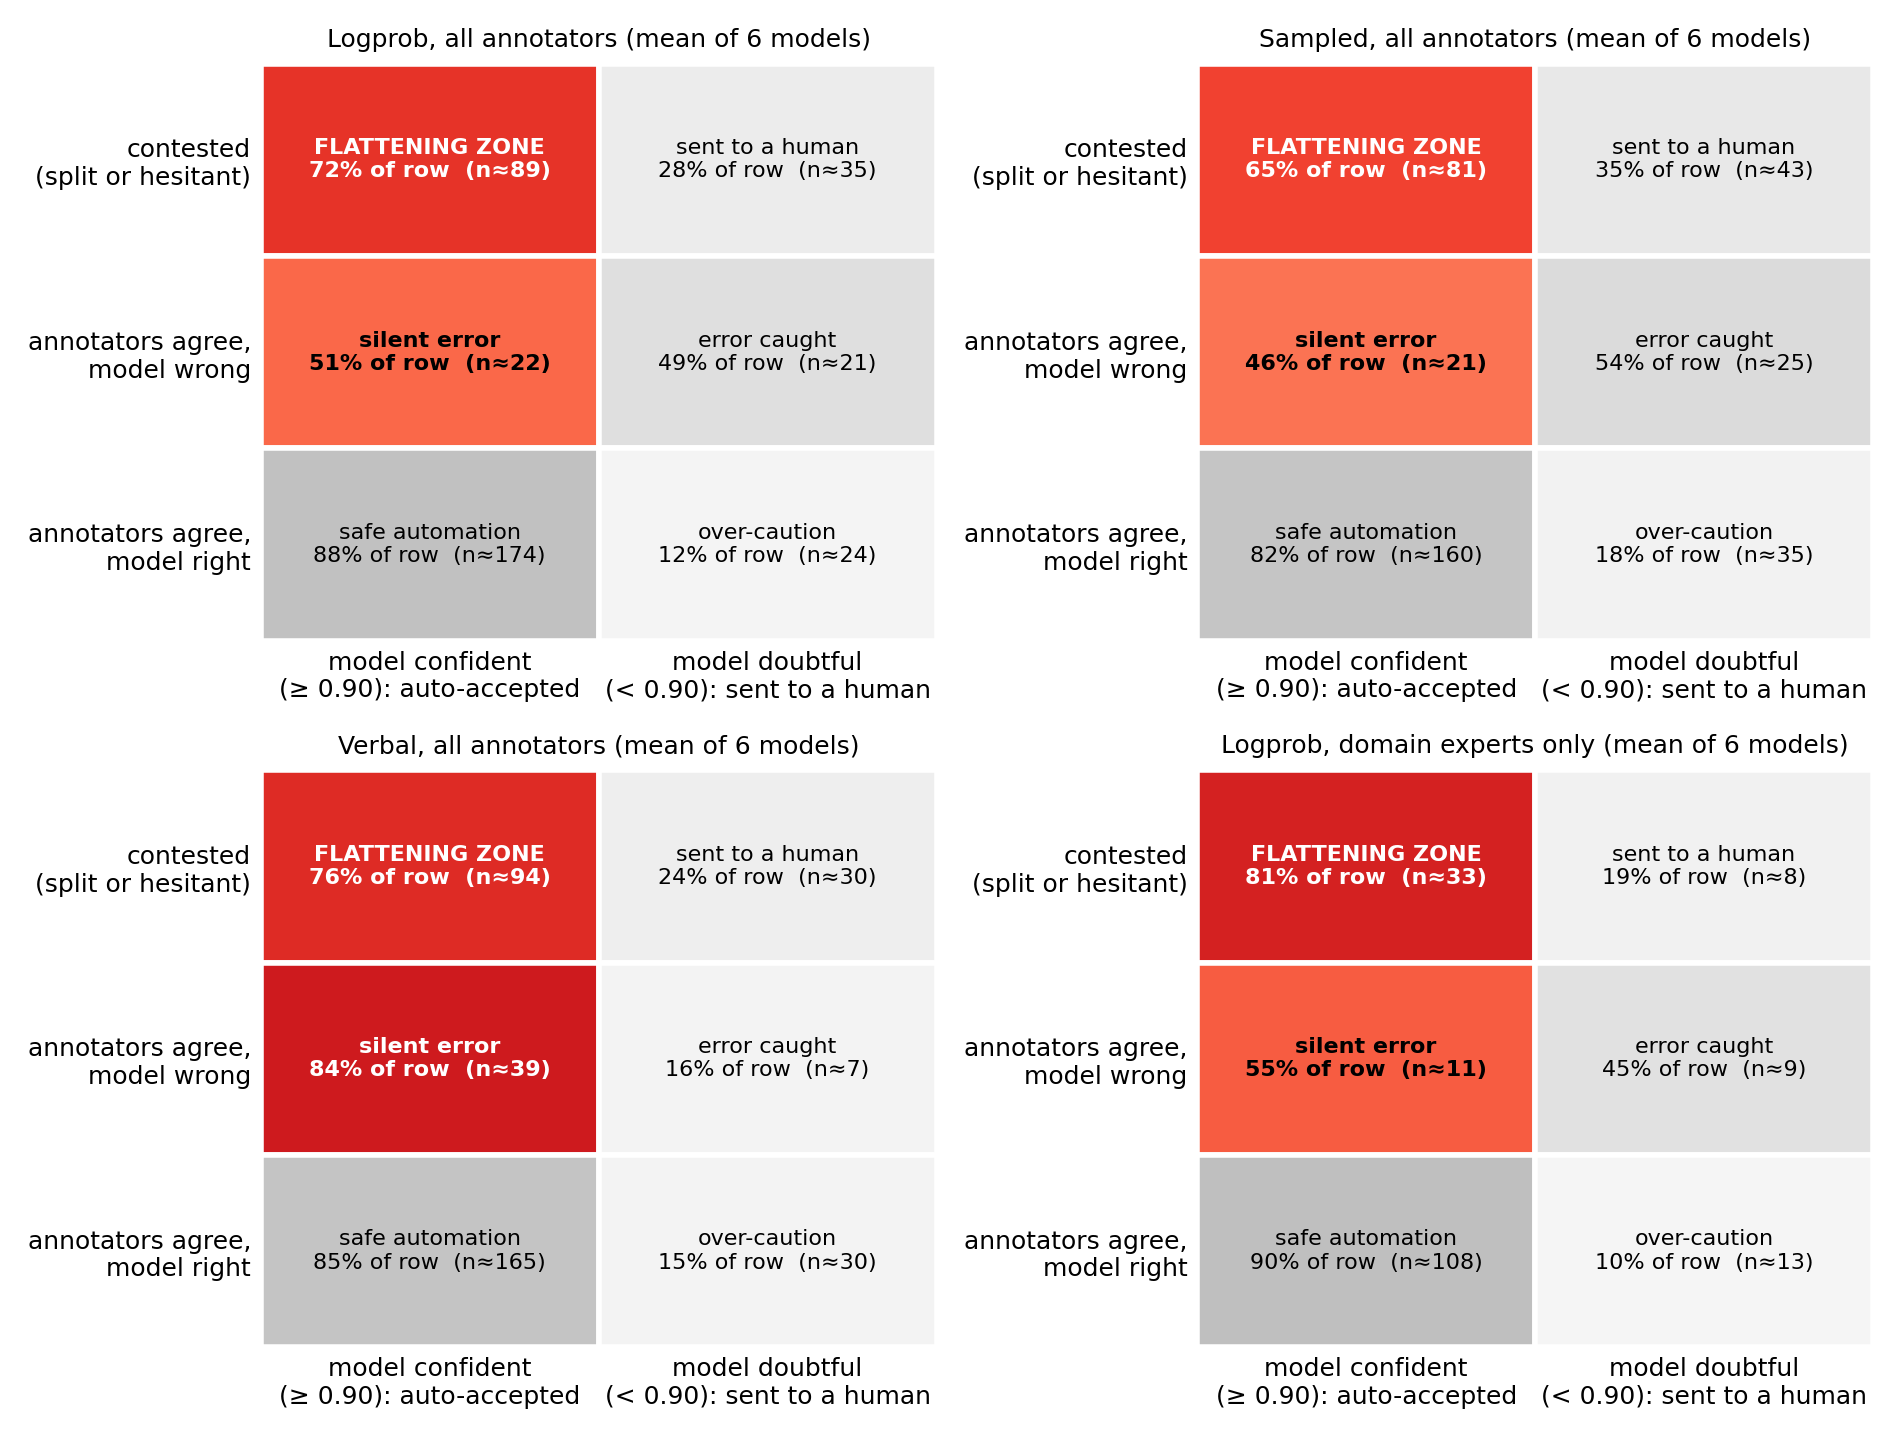

In [14]:
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
GCOL = {'easy': '#2ca02c', 'mislabelled': '#d62728', 'contested': '#9467bd'}
CELLS = {('contested', 'auto'): 'FLATTENING ZONE', ('contested', 'review'): 'sent to a human',
         ('mislabelled', 'auto'): 'silent error', ('mislabelled', 'review'): 'error caught',
         ('easy', 'auto'): 'safe automation', ('easy', 'review'): 'over-caution'}

panels = [('Logprob, all annotators', 'logprob', False), ('Sampled, all annotators', 'sampled', False),
          ('Verbal, all annotators', 'verbal', False), ('Logprob, domain experts only', 'logprob', True)]
fig, axs = plt.subplots(2, 2, figsize=(9.5, 7.2))
for a, (title, m, ee) in zip(axs.flat, panels):
    rs = [x[x.pair == 'expert-expert'] if ee else x for _, mm, x in runs if mm == m]
    for r, g in enumerate(['contested', 'mislabelled', 'easy']):
        share = np.mean([(x.consistency[x.group == g] >= TAU).mean() for x in rs])
        n = np.mean([(x.group == g).sum() for x in rs])
        for c, (dec, v) in enumerate([('auto', share), ('review', 1 - share)]):
            harm = (g, dec) in [('contested', 'auto'), ('mislabelled', 'auto')]
            colour = plt.cm.Reds(.15 + .7 * v) if harm else plt.cm.Greys(.05 + .35 * v)
            a.add_patch(plt.Rectangle((c, 2 - r), 1, 1, facecolor=colour, edgecolor='white', lw=2))
            a.text(c + .5, 2 - r + .5, f'{CELLS[(g, dec)]}\n{v:.0%} of row  (n≈{v * n:.0f})', ha='center', va='center',
                   fontsize=8, fontweight='bold' if harm else 'normal', color='white' if harm and v > .6 else 'black')
    a.set_xlim(0, 2); a.set_ylim(0, 3)
    a.set_xticks([.5, 1.5], [f'model confident\n(≥ {TAU:.2f}): auto-accepted', f'model doubtful\n(< {TAU:.2f}): sent to a human'])
    a.set_yticks([2.5, 1.5, .5], ['contested\n(split or hesitant)', 'annotators agree,\nmodel wrong', 'annotators agree,\nmodel right'])
    a.tick_params(length=0)
    for s in a.spines.values():
        s.set_visible(False)
    a.set_title(f'{title} (mean of {len(rs)} models)', fontsize=9)
fig.tight_layout()
path = os.path.join(FIG_DIR, 'fig5_sq3_outcomes.png')
fig.savefig(path, dpi=200); plt.close(fig)
display(Image(filename=path))

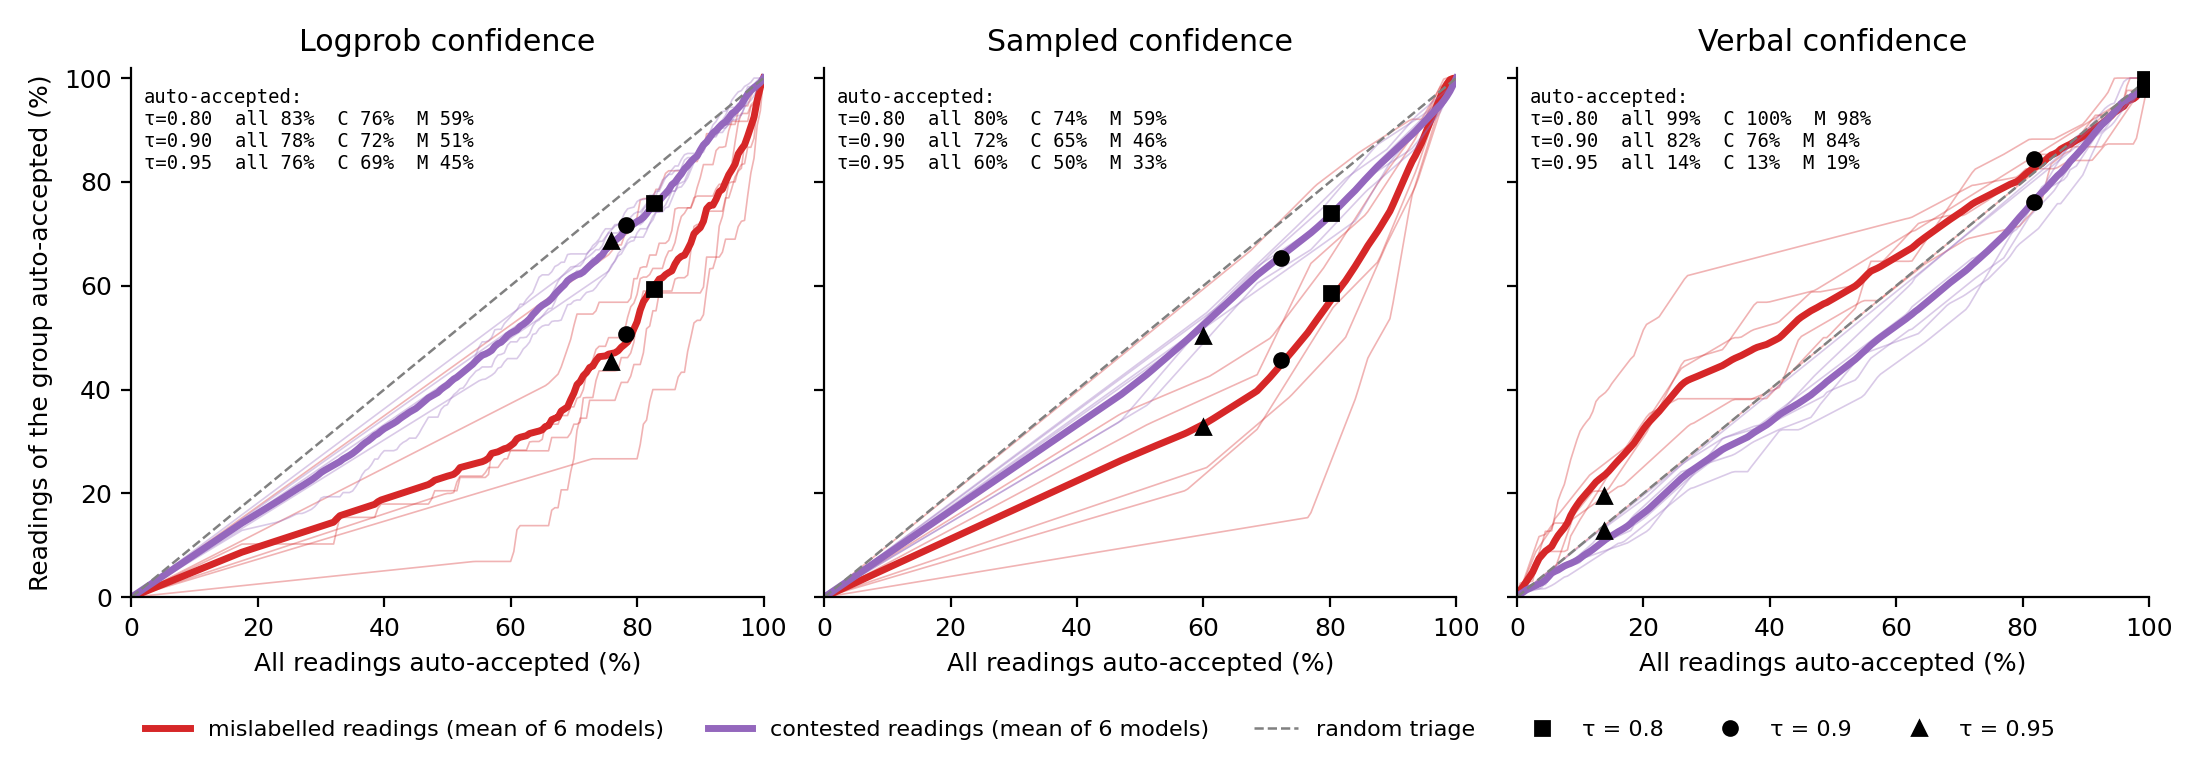

In [15]:
def triage_curve(x, grid):
    """Share of all readings auto-accepted (x) vs. share of each group auto-accepted, sweeping the threshold."""
    c = x.consistency.values
    taus = np.r_[np.inf, np.sort(np.unique(c))[::-1], -np.inf]
    xs = np.array([(c >= t).mean() for t in taus])
    return {g: np.interp(grid, xs, [(c[x.group.values == g] >= t).mean() for t in taus]) for g in ['contested', 'mislabelled']}

grid = np.linspace(0, 1, 201)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for a, m in zip(ax, MEASURES):
    rs = [x for _, mm, x in runs if mm == m]
    curves = [triage_curve(x, grid) for x in rs]
    for g in ['mislabelled', 'contested']:
        for cv in curves:
            a.plot(100 * grid, 100 * cv[g], color=GCOL[g], lw=.6, alpha=.35)
        a.plot(100 * grid, 100 * np.mean([cv[g] for cv in curves], axis=0), color=GCOL[g], lw=2.5,
               label=f'{g} readings (mean of {len(rs)} models)')
    a.plot([0, 100], [0, 100], color='grey', ls='--', lw=.9, label='random triage')
    lines = []
    for tau, mk in [(.8, 's'), (.9, 'o'), (.95, '^')]:
        px = np.mean([(x.consistency >= tau).mean() for x in rs])
        py = {g: np.mean([(x.consistency[x.group == g] >= tau).mean() for x in rs]) for g in ['contested', 'mislabelled']}
        for g, v in py.items():
            a.plot(100 * px, 100 * v, mk, color='k', ms=5, zorder=5, label=f'τ = {tau}' if g == 'contested' else None)
        lines.append(f'τ={tau:.2f}  all {px:.0%}  C {py["contested"]:.0%}  M {py["mislabelled"]:.0%}')
    a.text(2, 98, 'auto-accepted:\n' + '\n'.join(lines), va='top', fontsize=6.8, family='monospace')
    a.set_xlim(0, 100); a.set_ylim(0, 102)
    a.set_title(f'{m.capitalize()} confidence')
    a.set_xlabel('All readings auto-accepted (%)')
ax[0].set_ylabel('Readings of the group auto-accepted (%)')
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, loc='lower center', ncol=6, fontsize=8)
fig.tight_layout(rect=(0, .07, 1, 1))
path = os.path.join(FIG_DIR, 'fig_triage.png')
fig.savefig(path, dpi=200); plt.close(fig)
display(Image(filename=path))

## Step 7 — Recap: where each number appears in the paper

| Paper | Number | Step |
|---|---|---|
| §2.5 | templates disagree on 14–27% of readings | 1 |
| §3.4 | easy 88%, contested 72%, mistakes 51% auto-accepted; agreed 82%; ratio .88 [.79, .99]; experts .96 [.88, 1.06] | 2 |
| §3.4, Appendix Table *Contested readings by type* | label splits 67%, hesitancy only 68–81% depending on the source of doubt; 76% match an annotator; 76% agreed label | 2 |
| §3.4 and footnote | protest: 47 moves away vs. 12 toward; 22 of 47 to Memory; from 10 readings in 3 texts; only two models significant; texts 3 vs. 3; Truth-seeking 210 vs. 15, 16 texts vs. 0, 113 moves to Organisation; all spans balanced (59 Organisation → protest) | 3 |
| §3.4, §3.5, Appendix Table *Routing* | confidence +31 mistakes / +9 contested at 40%; category +12; experts at 20% +20 vs. +7; two buckets +10 / +24, experts +20 / +33 | 4 |
| §3.5, Appendix Table *Alternative routing signals* | second-best label .50; partner label among samples 44–65%; other five models .80 / .61; all six agree 50% / 39% | 5 |
| Figures *Outcomes* and *Triage trade-off* | | 6 |